In [1]:
import pandas as pd
from sqlalchemy import create_engine

server = "BRIGHTPEUTE0183\\SQLEXPRESS"
database = "Fontys_Carleon"

connection_string = (
    f"mssql+pyodbc://@{server}/{database}"
    "?driver=ODBC+Driver+17+for+SQL+Server"
    "&trusted_connection=yes"
)

engine = create_engine(connection_string)

amutas = pd.read_sql("SELECT * FROM amutas", engine)
amutak = pd.read_sql("SELECT * FROM amutak", engine)
BankTransactions = pd.read_sql("SELECT * FROM BankTransactions", engine)
cicmpy = pd.read_sql("SELECT * FROM cicmpy", engine)
gbkmut = pd.read_sql("SELECT * FROM gbkmut", engine)
dagbk = pd.read_sql("SELECT * FROM dagbk", engine)
grtbk = pd.read_sql("SELECT * FROM grtbk", engine)


In [2]:
gbkmut = gbkmut[[
    "datum",
    "faktuurnr",
    "bdr_hfl",
    "debnr",
    "ReconcileNumber",
    "reknr",
    "dagbknr",
    "betaalref"
]]

cicmpy = cicmpy[[
    "debnr",
    "cmp_name",
    "cmp_wwn",
    "PaymentCondition"
]]

grtbk = grtbk[[
    "reknr",
    "omzrek"
]]

dagbk = dagbk[[
    "dagbknr",
    "type_dgbk"
]]

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

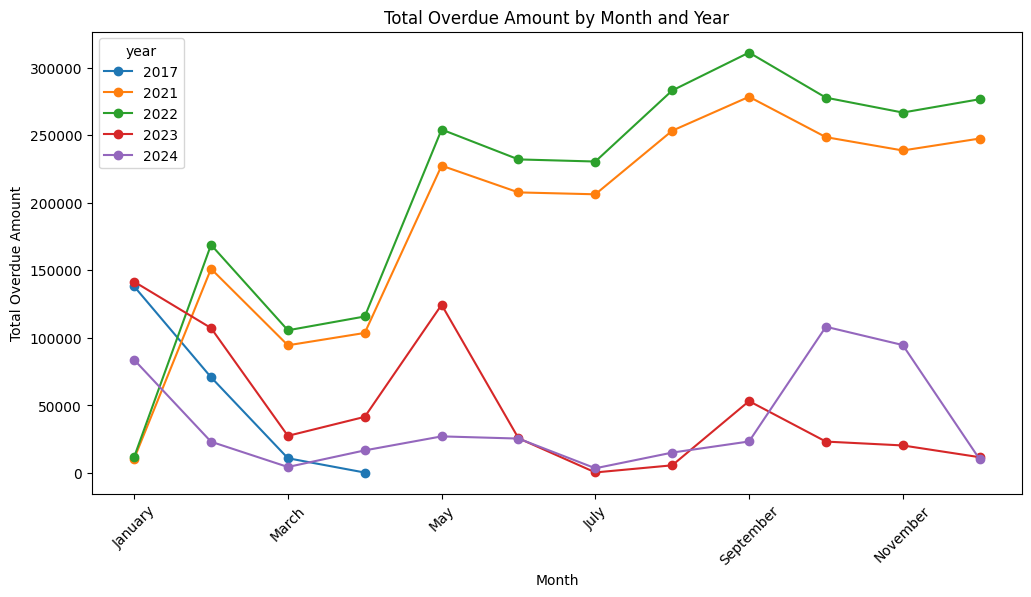

In [83]:
gbkmut['reknr'] = gbkmut['reknr'].str.strip()

# filter debtor ledger
overdue = gbkmut[
    gbkmut['reknr'] == '221001'
]

# create year and month
overdue['year'] = overdue['datum'].dt.year
overdue['month'] = overdue['datum'].dt.month_name()

# group
monthly_overdue = overdue.groupby(
    ['month', 'year']
)['bdr_hfl'].sum().unstack().abs()

# reorder months
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_overdue = monthly_overdue.reindex(month_order)

# plot
monthly_overdue.plot(
    figsize=(12,6),
    marker='o'
)

plt.title('Total Overdue Amount by Month and Year')
plt.xlabel('Month')
plt.ylabel('Total Overdue Amount')

plt.xticks(rotation=45)

plt.show()

debnr
813845          1.455192e-11
736740          2.728484e-12
735619          2.728484e-12
732198          2.501110e-12
734469          2.387424e-12
734771          2.273737e-12
735590          2.046363e-12
734456          2.046363e-12
734470          1.932676e-12
734540          1.932676e-12
Name: bdr_hfl, dtype: float64


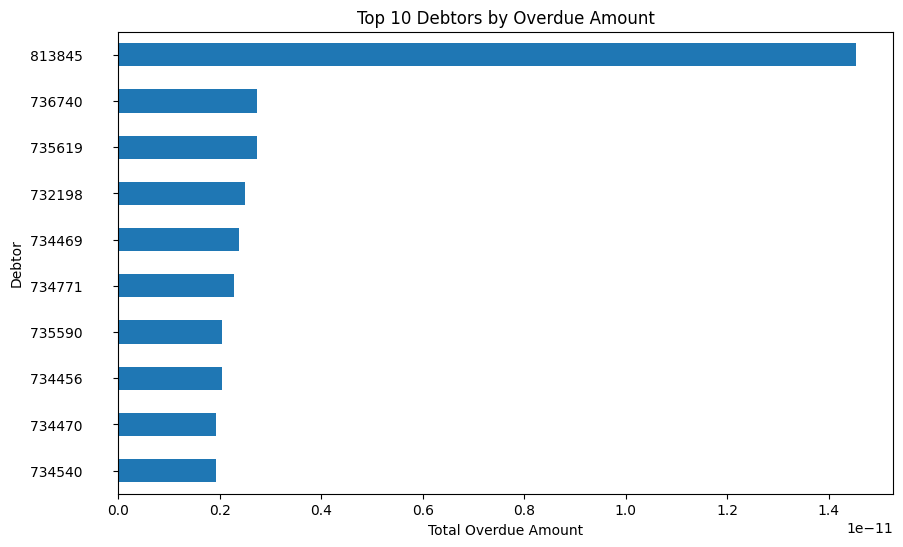

In [57]:
top_debtors = gbkmut.groupby(
    'debnr'
)['bdr_hfl'].sum().abs()

top_10 = top_debtors.sort_values(
    ascending=False
).head(10)

print(top_10)

top_10.plot(
    kind='barh',
    figsize=(10,6)
)

plt.title('Top 10 Debtors by Overdue Amount')
plt.xlabel('Total Overdue Amount')
plt.ylabel('Debtor')

plt.gca().invert_yaxis()

plt.show()

In [28]:
# convert dates
BankTransactions['InvoiceDate'] = pd.to_datetime(
    BankTransactions['InvoiceDate']
)

BankTransactions['ProcessingDate'] = pd.to_datetime(
    BankTransactions['ProcessingDate']
)

# calculate DSO
BankTransactions['DSO'] = (
    BankTransactions['ProcessingDate']
    - BankTransactions['InvoiceDate']
).dt.days

# remove negative or missing values
dso_clean = BankTransactions[
    BankTransactions['DSO'] >= 0
]

# average DSO
dso = dso_clean['DSO'].mean()

print(round(dso, 1))

38.4


In [27]:
BankTransactions['PaymentDays'].describe()

count    806144.000000
mean          0.005200
std           0.350955
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          60.000000
Name: PaymentDays, dtype: float64

In [33]:
BankTransactions['AmountDC'].describe()

count    963092.000000
mean         78.887482
std        1562.545871
min      -69934.500000
25%        -241.918500
50%          63.214500
75%         382.568000
max       68769.130000
Name: AmountDC, dtype: float64

In [37]:
BankTransactions.groupby(
    'TransactionType'
)['AmountDC'].sum()

TransactionType
C   -1.057229e+08
K    2.246643e+08
N   -4.296550e+07
Y    0.000000e+00
Z    0.000000e+00
Name: AmountDC, dtype: float64

In [40]:
overdue = BankTransactions[
    (BankTransactions['TransactionType'] == 'C') &
    (BankTransactions['DueDate'] < pd.Timestamp.today())
]

total_overdue = overdue['AmountDC'].sum()

print(abs(round(total_overdue, 2)))

105722918.42


In [52]:
BankTransactions['payment_time'] = (
    BankTransactions['ProcessingDate']
    - BankTransactions['InvoiceDate']
).dt.days

# remove negatives and nulls
BankTransactions = BankTransactions[
    (BankTransactions['payment_time'] >= 0)
]

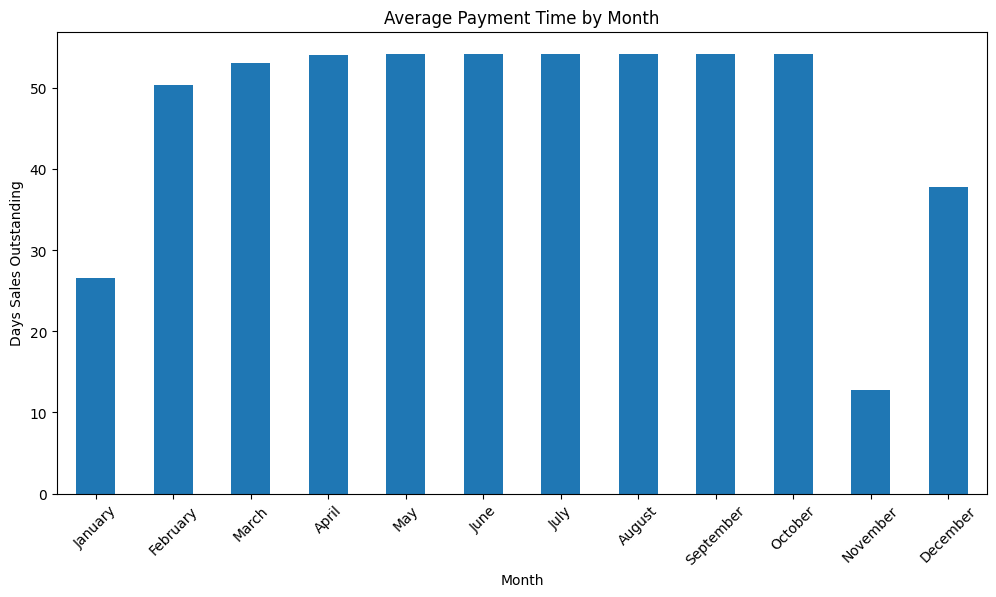

In [55]:
# convert dates
BankTransactions['InvoiceDate'] = pd.to_datetime(
    BankTransactions['InvoiceDate']
)

BankTransactions['ProcessingDate'] = pd.to_datetime(
    BankTransactions['ProcessingDate']
)

# calculate payment time
BankTransactions['payment_time'] = (
    BankTransactions['ProcessingDate']
    - BankTransactions['InvoiceDate']
).dt.days

# remove invalid values
BankTransactions = BankTransactions[
    BankTransactions['payment_time'] >= 0
]

# use processing month
BankTransactions['month'] = BankTransactions[
    'ProcessingDate'
].dt.month_name()

# average payment time by month
avg_payment = BankTransactions.groupby(
    'month'
)['payment_time'].mean()

# reorder months
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

avg_payment = avg_payment.reindex(month_order)

# plot column chart
avg_payment.plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Average Payment Time by Month')
plt.xlabel('Month')
plt.ylabel('Days Sales Outstanding')

plt.xticks(rotation=45)

plt.show()

In [84]:
# total outstanding amount
total_outstanding = gbkmut[
    gbkmut['reknr'] == '221001'
]['bdr_hfl'].sum()

# make positive
total_outstanding = abs(total_outstanding)

print(round(total_outstanding, 2))

5021651.3


In [3]:
# convert dates
BankTransactions['InvoiceDate'] = pd.to_datetime(
    BankTransactions['InvoiceDate']
)

BankTransactions['ProcessingDate'] = pd.to_datetime(
    BankTransactions['ProcessingDate']
)

# calculate DSO
BankTransactions['DSO'] = (
    BankTransactions['ProcessingDate']
    - BankTransactions['InvoiceDate']
).dt.days

# remove negatives
BankTransactions = BankTransactions[
    BankTransactions['DSO'] >= 0
]

# average DSO
dso = BankTransactions['DSO'].mean()

print(round(dso, 2))

38.37


year
2017     0.00
2021    37.08
2022    38.48
2023    58.00
2024    58.00
2025    58.00
Name: DSO, dtype: float64


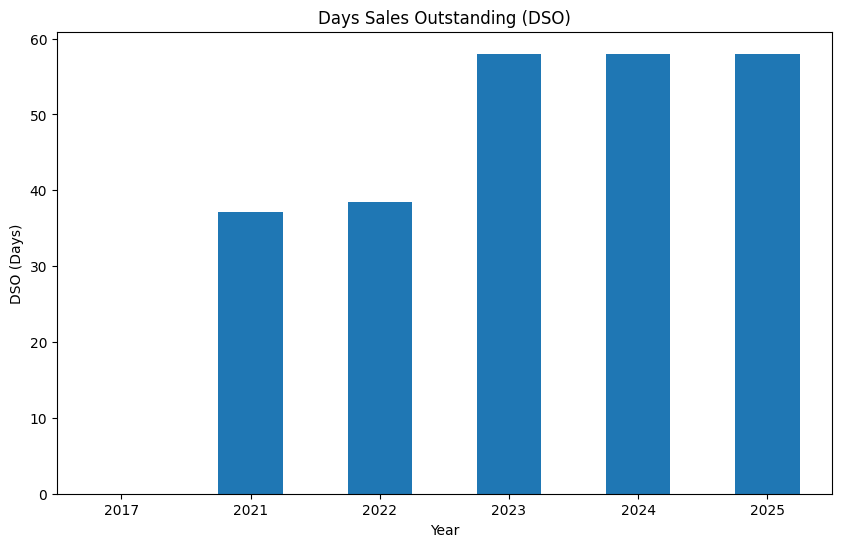

In [7]:
# convert dates
BankTransactions['InvoiceDate'] = pd.to_datetime(
    BankTransactions['InvoiceDate']
)

BankTransactions['ProcessingDate'] = pd.to_datetime(
    BankTransactions['ProcessingDate']
)

# calculate DSO days
BankTransactions['DSO'] = (
    BankTransactions['ProcessingDate']
    - BankTransactions['InvoiceDate']
).dt.days

# remove invalid values
BankTransactions = BankTransactions[
    BankTransactions['DSO'] >= 0
]

# create year
BankTransactions['year'] = BankTransactions[
    'ProcessingDate'
].dt.year

# yearly DSO
yearly_dso = BankTransactions.groupby(
    'year'
)['DSO'].mean()

print(round(yearly_dso, 2))

# plot
yearly_dso.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Days Sales Outstanding (DSO)')
plt.xlabel('Year')
plt.ylabel('DSO (Days)')

plt.xticks(rotation=0)

plt.show()

year
2017      1.53
2021    -39.83
2022    -39.83
2023    195.25
2024    232.90
Name: AmountDC, dtype: float64


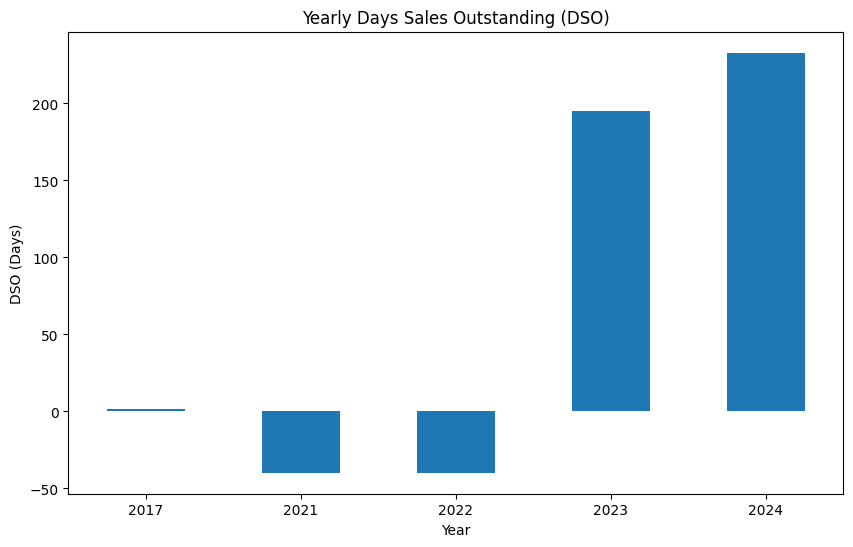

In [11]:
# convert date
BankTransactions['InvoiceDate'] = pd.to_datetime(
    BankTransactions['InvoiceDate']
)

# create year
BankTransactions['year'] = BankTransactions[
    'InvoiceDate'
].dt.year

# yearly total sales
sales = BankTransactions.groupby(
    'year'
)['AmountDC'].sum()

# yearly accounts receivable
receivables = BankTransactions[
    BankTransactions['MatchID'].isna()
].groupby(
    'year'
)['AmountDC'].sum()

# calculate DSO
yearly_dso = (
    receivables / sales
) * 365

print(round(yearly_dso, 2))

# plot
yearly_dso.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Yearly Days Sales Outstanding (DSO)')
plt.xlabel('Year')
plt.ylabel('DSO (Days)')

plt.xticks(rotation=0)

plt.show()